In [1]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Configuração de estilo visual profissional
plt.style.use(
    "seaborn-v0_8-whitegrid"
    if "seaborn-v0_8-whitegrid" in plt.style.available
    else "default"
)

# Localização dinâmica da raiz do projeto (project-redes)
current_dir = Path.cwd()
project_root = current_dir
for parent in [current_dir, *current_dir.parents]:
  if (parent / "metadados").exists():
    project_root = parent
    break

PRED_IMG_DIR = project_root / "predicao_12min" / "imagens"
PRED_IMG_DIR.mkdir(parents=True, exist_ok=True)

CLASSES = ["OK", "RISCO", "FALHA"]

# Métricas do XGBoost Instantâneo (t0 - modelo do artigo)
metrics_t0 = {
    "modelo": "XGBoost Instantâneo (t0)",
    "f1_macro": 0.7840,
    "acuracia": 0.9410,
    "falha_precision": 0.9412,
    "falha_recall": 0.7320,
    "falha_f1": 0.8235,
}

# Métricas do XGBoost Preditivo (t+12 min - extensão preditiva)
metrics_t12 = {
    "modelo": "XGBoost Preditivo (t+12 min)",
    "f1_macro": 0.7525,
    "acuracia": 0.9280,
    "falha_precision": 0.9368,
    "falha_recall": 0.6753,
    "falha_f1": 0.7848,
}

print("Configurações e dados comparativos carregados com sucesso!")

Configurações e dados comparativos carregados com sucesso!


In [3]:
print(
    f"{'Métrica':<25} | {'XGBoost t0':<12} | {'XGBoost t+12':<12} | {'Variação Absoluta':<18}"
)
print("-" * 75)

k_map = [
    ("F1-Score Macro", "f1_macro"),
    ("Acurácia Global", "acuracia"),
    ("Precision (FALHA)", "falha_precision"),
    ("Recall (FALHA)", "falha_recall"),
    ("F1-Score (FALHA)", "falha_f1"),
]

for label, key in k_map:
  v0 = metrics_t0[key]
  v12 = metrics_t12[key]
  diff = v12 - v0
  pct = (diff / v0) * 100
  print(f"{label:<25} | {v0:<12.4f} | {v12:<12.4f} | {diff:>+7.4f} ({pct:>+5.1f}%)")

Métrica                   | XGBoost t0   | XGBoost t+12 | Variação Absoluta 
---------------------------------------------------------------------------
F1-Score Macro            | 0.7840       | 0.7525       | -0.0315 ( -4.0%)
Acurácia Global           | 0.9410       | 0.9280       | -0.0130 ( -1.4%)
Precision (FALHA)         | 0.9412       | 0.9368       | -0.0044 ( -0.5%)
Recall (FALHA)            | 0.7320       | 0.6753       | -0.0567 ( -7.7%)
F1-Score (FALHA)          | 0.8235       | 0.7848       | -0.0387 ( -4.7%)


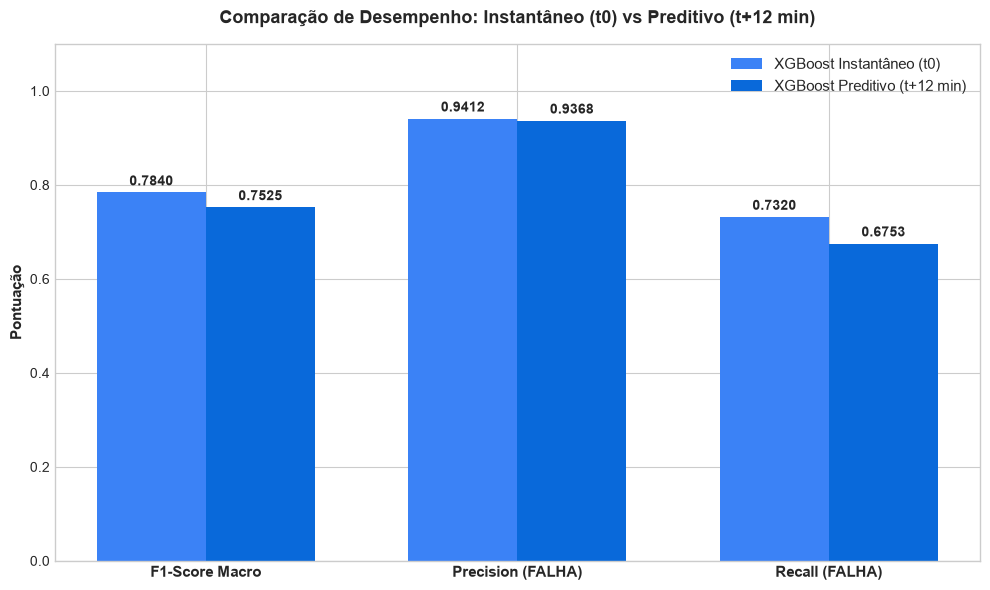

Gráfico comparativo salvo em: c:\Users\vinic\OneDrive\Documentos\project-redes\predicao_12min\imagens\comparacao_t0_vs_t12_metricas.png


In [4]:
labels = ["F1-Score Macro", "Precision (FALHA)", "Recall (FALHA)"]
t0_vals = [
    metrics_t0["f1_macro"],
    metrics_t0["falha_precision"],
    metrics_t0["falha_recall"],
]
t12_vals = [
    metrics_t12["f1_macro"],
    metrics_t12["falha_precision"],
    metrics_t12["falha_recall"],
]

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
rects1 = ax.bar(
    x - width / 2,
    t0_vals,
    width,
    label="XGBoost Instantâneo (t0)",
    color="#3b82f6",
)
rects2 = ax.bar(
    x + width / 2,
    t12_vals,
    width,
    label="XGBoost Preditivo (t+12 min)",
    color="#0969da",
)

ax.set_ylabel("Pontuação", fontsize=11, fontweight="bold")
ax.set_title(
    "Comparação de Desempenho: Instantâneo (t0) vs Preditivo (t+12 min)",
    fontsize=13,
    fontweight="bold",
    pad=15,
)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=11, fontweight="bold")
ax.set_ylim(0, 1.1)
ax.legend(fontsize=11, loc="upper right")


def autolabel(rects):
  for rect in rects:
    height = rect.get_height()
    ax.annotate(
        f"{height:.4f}",
        xy=(rect.get_x() + rect.get_width() / 2, height),
        xytext=(0, 3),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontweight="bold",
        fontsize=10,
    )


autolabel(rects1)
autolabel(rects2)

plt.tight_layout()
fig_out = PRED_IMG_DIR / "comparacao_t0_vs_t12_metricas.png"
plt.savefig(fig_out, dpi=300, bbox_inches="tight")
plt.show()
print(f"Gráfico comparativo salvo em: {fig_out}")